#Import pandas, matplotlib, mlxtend. from mlxtend import apriori and association rules. 
 set pandas display to width 140 and max columns to 20.

In [1]:
%pip install mlxtend

Note: you may need to restart the kernel to use updated packages.


In [2]:
from mlxtend.frequent_patterns import apriori, association_rules



In [3]:
import pandas as pd

%pip install matplotlib
import matplotlib.pyplot as plt

Note: you may need to restart the kernel to use updated packages.


In [4]:
# Setup is already performed in cell 2.

#Suppress warnings

In [5]:
import warnings

warnings.filterwarnings("ignore")

#Load csvs: customers-assoc, transactions-assoc, and transactions-assoc into dfs with shorten names.
print rows, columns, check for null values, and duplicate rows.
Then print the number of orphan customer_ids and product_ids in transactions that do not exist in customers or products tables.

In [6]:
customers = pd.read_csv("customers -assoc.csv")
transactions = pd.read_csv("transactions-assoc.csv")
products = pd.read_csv("products-assoc.csv")

parse the transaction date.

In [7]:
transactions["transaction_date"] = pd.to_datetime(transactions["transaction_date"], errors="coerce")

display the df for customers, products, transactions for 3 rows only. 

In [8]:
for name, df in [
    ("customers", customers),
    ("products", products),
    ("transactions", transactions),
]:
    print(f"--- {name} ---")
    display(df.head(3))

--- customers ---


,customer_id,name,age,region,segment,signup_date
0,C0001,Customer 1,23,North,Regular,2024-05-28
1,C0002,Customer 2,65,West,Premium,2022-03-04
2,C0003,Customer 3,58,Central,Premium,2023-02-02


--- products ---


,product_id,product_name,category,brand,price
0,P001,Pasta,Pantry,Harvest,1.8
1,P002,Pasta Sauce,Pantry,FreshCo,2.5
2,P003,Rice,Pantry,Harvest,2.2


--- transactions ---


,transaction_id,customer_id,product_id,quantity,unit_price,transaction_date
0,T00001,C0421,P028,3,3.0,2026-04-21
1,T00001,C0421,P031,1,1.3,2026-04-21
2,T00001,C0421,P006,1,1.6,2026-04-21


In [9]:
for name, df in [("customers", customers), ("transactions", transactions), ("products", products)]:
    print(f"--- {name} ---")
    print("Rows:", df.shape[0], "Columns:", df.shape[1])
    print("Null values per column:")
    print(df.isnull().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print()

orphan_customers = ~transactions["customer_id"].isin(customers["customer_id"])
orphan_products = ~transactions["product_id"].isin(products["product_id"])

print("Orphan customer_ids in transactions:", transactions.loc[orphan_customers, "customer_id"].nunique())
print("Orphan product_ids in transactions:", transactions.loc[orphan_products, "product_id"].nunique())

--- customers ---
Rows: 500 Columns: 6
Null values per column:
customer_id    0
name           0
age            0
region         0
segment        0
signup_date    0
dtype: int64
Duplicate rows: 0

--- transactions ---
Rows: 16377 Columns: 6
Null values per column:
transaction_id      0
customer_id         0
product_id          0
quantity            0
unit_price          0
transaction_date    0
dtype: int64
Duplicate rows: 0

--- products ---
Rows: 37 Columns: 5
Null values per column:
product_id      0
product_name    0
category        0
brand           0
price           0
dtype: int64
Duplicate rows: 0

Orphan customer_ids in transactions: 0
Orphan product_ids in transactions: 0


join the transactions with product ids on product id, then with customers on customer id (only use only customer id, segment and region) into a df. Add a revenue column (quantity * unit price). Print number of 'unique' baskets (based on transaction id) and line items.  

In [10]:
df = (
    transactions
    .merge(products, on="product_id", how="left")
    .merge(customers[["customer_id", "segment", "region"]], on="customer_id", how="left")
)

df["revenue"] = df["quantity"] * df["unit_price"]

print("Unique baskets:", df["transaction_id"].nunique())
print("Line items:", len(df))

df.head(3)

Unique baskets: 3000
Line items: 16377


,transaction_id,customer_id,product_id,quantity,unit_price,transaction_date,product_name,category,brand,price,segment,region,revenue
0,T00001,C0421,P028,3,3.0,2026-04-21,Eggs,Dairy,NatureBest,3.0,Budget,Central,9.0
1,T00001,C0421,P031,1,1.3,2026-04-21,Bananas,Produce,NatureBest,1.3,Budget,Central,1.3
2,T00001,C0421,P006,1,1.6,2026-04-21,Flour,Pantry,FreshCo,1.6,Budget,Central,1.6


Use df, draw 3 side by side matplotlib charts in 1 figure (16x4).
show top 10 products by number of unique baskets, basket size distribution (histogram of distinct products per transaction id) and revenue by category. Use plt.tight_layout() and plt.show(). use three distincts colours for the 3 charts. 


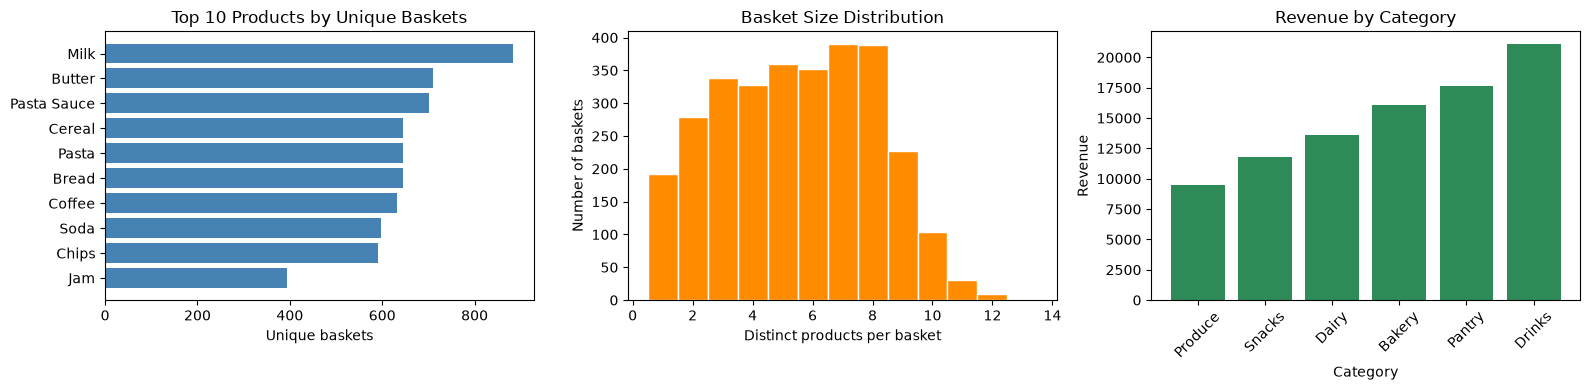

In [11]:
top_products = (
    df.groupby("product_name")["transaction_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

basket_sizes = df.groupby("transaction_id")["product_id"].nunique()

revenue_by_category = df.groupby("category")["revenue"].sum().sort_values()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].barh(top_products.index, top_products.values, color="steelblue")
axes[0].set_title("Top 10 Products by Unique Baskets")
axes[0].set_xlabel("Unique baskets")

axes[1].hist(basket_sizes, bins=range(1, basket_sizes.max() + 2), color="darkorange", edgecolor="white", align="left")
axes[1].set_title("Basket Size Distribution")
axes[1].set_xlabel("Distinct products per basket")
axes[1].set_ylabel("Number of baskets")

axes[2].bar(revenue_by_category.index, revenue_by_category.values, color="seagreen")
axes[2].set_title("Revenue by Category")
axes[2].set_xlabel("Category")
axes[2].set_ylabel("Revenue")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# define a function build basket (data) which returns a boolean df with 1 row per transaction id and 1 column per product name (use pd.crosstab) and convert to boolean. call df basket, print basket.shape. display first 5 rows and columns.

In [12]:
def build_basket(data):
    return pd.crosstab(data["transaction_id"], data["product_name"]).astype(bool)

basket = build_basket(df)

print("Basket shape:", basket.shape)
display(basket.iloc[:5, :5])

Basket shape: (3000, 37)


product_name,Apples,Bagels,Bananas,Beer,Bread
transaction_id,,,,,
T00001,False,False,True,False,False
T00002,False,True,False,False,True
T00003,False,True,False,True,True
T00004,False,False,False,False,True
T00005,False,False,True,False,False


use apriori on basket with min support=0.02, usecolnames=True and max_len = 2. save the result as frequent. Add a size column (number of items in each itemset). Print how many itemsets are of each size and show the Top 10 by support. 

In [13]:
from mlxtend.frequent_patterns import apriori, association_rules

frequent = apriori(basket, min_support=0.02, use_colnames=True, max_len=2)
frequent["size"] = frequent["itemsets"].apply(len)

print(frequent["size"].value_counts().sort_index())
display(frequent.sort_values("support", ascending=False).head(10))

size
1     37
2    304
Name: count, dtype: int64


,support,itemsets,size
21,0.294667,frozenset({Milk}),1
5,0.236667,frozenset({Butter}),1
28,0.234000,frozenset({Pasta Sauce}),1
7,0.215333,frozenset({Cereal}),1
27,0.215000,frozenset({Pasta}),1
4,0.214667,frozenset({Bread}),1
11,0.210333,frozenset({Coffee}),1
32,0.199333,frozenset({Soda}),1
9,0.197000,frozenset({Chips}),1
314,0.144667,"frozenset({Pasta Sauce, Pasta})",2


Use mlxtend association_rules on frequent with metric="lift" and min_threshold=1.2, saving it as rules. 
Add a readable "rule" column in the form "Pasta  ->  Pasta Sauce" (sorted item names joined by commas, antecedent then consequent). 
Define cols = ["rule","support","confidence","lift"], print the number of rules, and show the top 10 sorted by lift, rounded to 2 decimals.

In [14]:
rules = association_rules(frequent, metric="lift", min_threshold=1.2)

rules["rule"] = (
    rules["antecedents"].apply(lambda x: ", ".join(sorted(x)))
    + "  ->  "
    + rules["consequents"].apply(lambda x: ", ".join(sorted(x)))
)

cols = ["rule", "support", "confidence", "lift"]

print("Number of rules:", len(rules))
display(rules.sort_values("lift", ascending=False)[cols].head(10).round(2))

Number of rules: 70


,rule,support,confidence,lift
58,Pasta Sauce -> Pasta,0.14,0.62,2.88
59,Pasta -> Pasta Sauce,0.14,0.67,2.88
31,Soda -> Chips,0.11,0.56,2.84
30,Chips -> Soda,0.11,0.57,2.84
13,Bread -> Butter,0.13,0.61,2.58
12,Butter -> Bread,0.13,0.55,2.58
35,Milk -> Coffee,0.13,0.45,2.14
34,Coffee -> Milk,0.13,0.63,2.14
29,Cereal -> Milk,0.12,0.55,1.86
28,Milk -> Cereal,0.12,0.40,1.86


filters rules to confidence >= 0.4 and lift >= 1.5, sorted by lift descending, saved as strong. Print how many strong rules there are and display them using the cols list, rounded to 3 decimals with the index reset.

In [15]:
strong = (
    rules.loc[(rules["confidence"] >= 0.4) & (rules["lift"] >= 1.5)]
    .sort_values("lift", ascending=False)
)

print("Number of strong rules:", len(strong))
display(strong[cols].round(3).reset_index(drop=True))

Number of strong rules: 10


,rule,support,confidence,lift
0,Pasta -> Pasta Sauce,0.145,0.673,2.876
1,Pasta Sauce -> Pasta,0.145,0.618,2.876
2,Soda -> Chips,0.112,0.560,2.844
3,Chips -> Soda,0.112,0.567,2.844
4,Bread -> Butter,0.131,0.610,2.579
5,Butter -> Bread,0.131,0.554,2.579
6,Milk -> Coffee,0.132,0.449,2.135
7,Coffee -> Milk,0.132,0.629,2.135
8,Milk -> Cereal,0.118,0.402,1.865
9,Cereal -> Milk,0.118,0.550,1.865


Create a 1x2 matplotlib figure (15x5). Left: scatter of rules support (x) vs confidence (y), coloured by lift using the viridis colormap with a colorbar labelled "Lift". 
Right: horizontal bar chart of the top 10 rules in strong by lift, using the "rule" column as labels with the highest lift at the top. 
Add titles and axis labels, then plt.tight_layout() and plt.show().

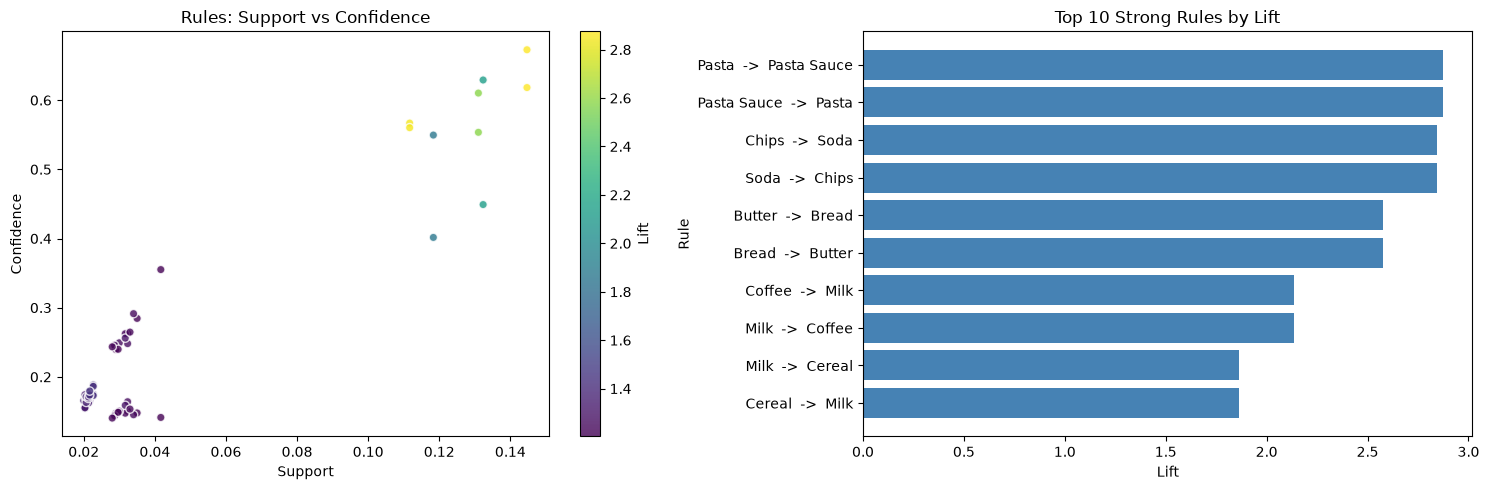

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sc = axes[0].scatter(
    rules["support"],
    rules["confidence"],
    c=rules["lift"],
    cmap="viridis",
    alpha=0.8,
    edgecolor="white",
)
fig.colorbar(sc, ax=axes[0], label="Lift")
axes[0].set_title("Rules: Support vs Confidence")
axes[0].set_xlabel("Support")
axes[0].set_ylabel("Confidence")

top_strong = strong.head(10).sort_values("lift")
axes[1].barh(top_strong["rule"], top_strong["lift"], color="steelblue")
axes[1].set_title("Top 10 Strong Rules by Lift")
axes[1].set_xlabel("Lift")
axes[1].set_ylabel("Rule")

plt.tight_layout()
plt.show()

Defines recommend(product_name, n=3, rules_df=rules). It should find rules where the antecedent is exactly that single product, sort by lift then confidence descending, and return a DataFrame with columns recommend, confidence and lift, rounded to 2 decimals. Then loop over ["Pasta","Chips","Bread","Coffee"] and print "Customers who buy X also buy:" followed by the result table.

In [17]:
def recommend(product_name, n=3, rules_df=rules):
    matches = rules_df[rules_df["antecedents"].apply(lambda x: x == frozenset([product_name]))]
    matches = matches.sort_values(["lift", "confidence"], ascending=False).head(n)
    result = pd.DataFrame({
        "recommend": matches["consequents"].apply(lambda x: ", ".join(sorted(x))),
        "confidence": matches["confidence"],
        "lift": matches["lift"],
    })
    return result.round(2).reset_index(drop=True)

for product in ["Pasta", "Chips", "Bread", "Coffee"]:
    print(f"Customers who buy {product} also buy:")
    display(recommend(product))
    print()

Customers who buy Pasta also buy:


,recommend,confidence,lift
0,Pasta Sauce,0.67,2.88
1,Tea,0.15,1.23



Customers who buy Chips also buy:


,recommend,confidence,lift
0,Soda,0.57,2.84
1,Carrots,0.16,1.26
2,Bagels,0.15,1.22



Customers who buy Bread also buy:


,recommend,confidence,lift
0,Butter,0.61,2.58
1,Rice,0.15,1.22
2,Tomatoes,0.15,1.22



Customers who buy Coffee also buy:


,recommend,confidence,lift
0,Milk,0.63,2.14


generate a cell that loops over df.groupby("segment"). For each segment, build the basket matrix with build_basket, run apriori (min_support=0.02, use_colnames=True, max_len=2), then association_rules (lift >= 1.2), and add the readable "rule" column. Store each result in a dict called segment_rules, and print the segment name, number of baskets, number of rules, and the top 5 rules by lift using cols.

In [18]:
segment_rules = {}

for segment, seg_df in df.groupby("segment"):
    seg_basket = build_basket(seg_df)
    seg_frequent = apriori(seg_basket, min_support=0.02, use_colnames=True, max_len=2)
    seg_rules = association_rules(seg_frequent, metric="lift", min_threshold=1.2)

    seg_rules["rule"] = (
        seg_rules["antecedents"].apply(lambda x: ", ".join(sorted(x)))
        + "  ->  "
        + seg_rules["consequents"].apply(lambda x: ", ".join(sorted(x)))
    )

    segment_rules[segment] = seg_rules

    print(f"--- Segment: {segment} ---")
    print("Baskets:", seg_basket.shape[0])
    print("Rules:", len(seg_rules))
    display(seg_rules.sort_values("lift", ascending=False)[cols].head(5).round(2))
    print()

--- Segment: Budget ---
Baskets: 946
Rules: 210


,rule,support,confidence,lift
84,Chips -> Soda,0.11,0.58,2.87
85,Soda -> Chips,0.11,0.56,2.87
191,Pasta -> Pasta Sauce,0.14,0.62,2.73
190,Pasta Sauce -> Pasta,0.14,0.62,2.73
40,Butter -> Bread,0.14,0.58,2.52



--- Segment: Premium ---
Baskets: 641
Rules: 280


,rule,support,confidence,lift
258,Pasta Sauce -> Pasta,0.15,0.63,3.12
259,Pasta -> Pasta Sauce,0.15,0.75,3.12
144,Chips -> Soda,0.10,0.55,2.74
145,Soda -> Chips,0.10,0.50,2.74
57,Bread -> Butter,0.11,0.57,2.63



--- Segment: Regular ---
Baskets: 1413
Rules: 116


,rule,support,confidence,lift
99,Pasta -> Pasta Sauce,0.14,0.68,2.88
98,Pasta Sauce -> Pasta,0.14,0.61,2.88
53,Soda -> Chips,0.12,0.59,2.87
52,Chips -> Soda,0.12,0.57,2.87
21,Bread -> Butter,0.13,0.61,2.59


Build a widget with dropdown box based on segment.

In [19]:
import ipywidgets as widgets
from IPython.display import clear_output

segment_dropdown = widgets.Dropdown(
    options=sorted(segment_rules.keys()),
    description="Segment:",
)

output = widgets.Output()

def show_segment_rules(change=None):
    segment = segment_dropdown.value
    with output:
        clear_output(wait=True)
        basket_count = df.loc[df["segment"] == segment, "transaction_id"].nunique()
        print(f"Segment: {segment} | Baskets: {basket_count}")
        display(
            segment_rules[segment]
            .sort_values("lift", ascending=False)[cols]
            .head(10)
            .round(2)
            .reset_index(drop=True)
        )

segment_dropdown.observe(show_segment_rules, names="value")
display(widgets.VBox([segment_dropdown, output]))
show_segment_rules()

"Business takeaways" 1. cross-sell bundles using high-lift pairs, shelf or web page placement, 2. tailoring offers by customer segment. But beware that Association Rules show correlation, not causation.